# Training a non-linear model (decision tree and random forest)

### Load imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import seaborn
from sklearn.exceptions import UndefinedMetricWarning
from datatypes import CLEAN_SQF
import warnings

# Silence warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

### Split dataset into training and testing sets

In [2]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

## Main analysis (decision tree)

### Create a decision tree model and tune hyperparameter

In [3]:
# Initialize decision tree model
dt = DecisionTreeClassifier(class_weight="balanced", random_state=123)

# Define how data should be split, using a specified seed
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid_dt = {"max_depth": [3, 5, 10, 20, None]}

scoring = ["accuracy", "precision", "recall", "f1"]

# Initialize GridSearchCV, with tuning based on recall (our primary metric)
dt_grid_search = GridSearchCV(
    dt,
    param_grid=param_grid_dt,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
)

# Run GridSearchCV
dt_grid_search.fit(X_train, y_train)

print(f"We evaluated 5 maximum depth values across 5 cross-validation folds, totaling 25 experimental fits. Using recall as our metric, the best hyperparameter was {dt_grid_search.best_params_}, which achieved a score of {dt_grid_search.best_score_:.2f}.")

We evaluated 5 maximum depth values across 5 cross-validation folds, totaling 25 experimental fits. Using recall as our metric, the best hyperparameter was {'max_depth': 5}, which achieved a score of 0.70.


### Display results

param_max_depth  mean_test_accuracy  rank_test_accuracy  mean_test_precision  rank_test_precision  mean_test_recall  rank_test_recall  mean_test_f1  rank_test_f1
              3                0.55                   5                 0.28                    5              0.69                 2          0.40             2
              5                0.56                   4                 0.29                    4              0.70                 1          0.41             1
             10                0.60                   3                 0.30                    3              0.61                 3          0.40             3
             20                0.64                   2                 0.31                    1              0.52                 4          0.39             4
           None                0.65                   1                 0.31                    2              0.48                 5          0.38             5


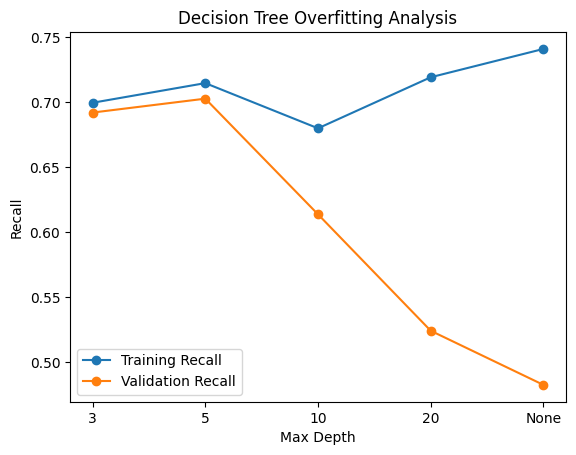

In [4]:
dt_grid_search_results = pd.DataFrame(dt_grid_search.cv_results_)

dt_results_table = dt_grid_search_results[[
    "param_max_depth",
    "mean_test_accuracy", "rank_test_accuracy",
    "mean_test_precision", "rank_test_precision",
    "mean_test_recall", "rank_test_recall",
    "mean_test_f1", "rank_test_f1"]].copy()

print(dt_results_table.to_string(index=False, float_format="%.2f"))

plt.figure()

x_vals = dt_grid_search_results["param_max_depth"].fillna("None").astype(str)

plt.plot(x_vals, dt_grid_search_results["mean_train_recall"], marker='o', label="Training Recall")
plt.plot(x_vals, dt_grid_search_results["mean_test_recall"], marker='o', label="Validation Recall")

plt.title("Decision Tree Overfitting Analysis")
plt.xlabel("Max Depth")
plt.ylabel("Recall")
plt.legend()
plt.show()

### Interpret model

Using the tuned hyperparameter, the Gini importance (feature contribution) for each feature is:

STOP_WAS_INITIATED_based on self initiated                                 0.525075
STOP_LOCATION_PATROL_BORO_NAME_pbbx                                        0.170413
STOP_LOCATION_PATROL_BORO_NAME_pbms                                        0.122841
SUSPECTED_CRIME_DESCRIPTION_cpw                                            0.049732
SUSPECT_REPORTED_AGE_<18                                                   0.021319
SUSPECTED_CRIME_DESCRIPTION_assault                                        0.016779
SUSPECT_REPORTED_AGE_25–44                                                 0.014862
SUSPECTED_CRIME_DESCRIPTION_cpsp                                           0.013702
STOP_LOCATION_PATROL_BORO_NAME_pbbs                                        0.013654
STOP_LOCATION_PATROL_BORO_NAME_pbmn                                        0.013610
SUSPECT_REPORTED_AGE_18–24                                     

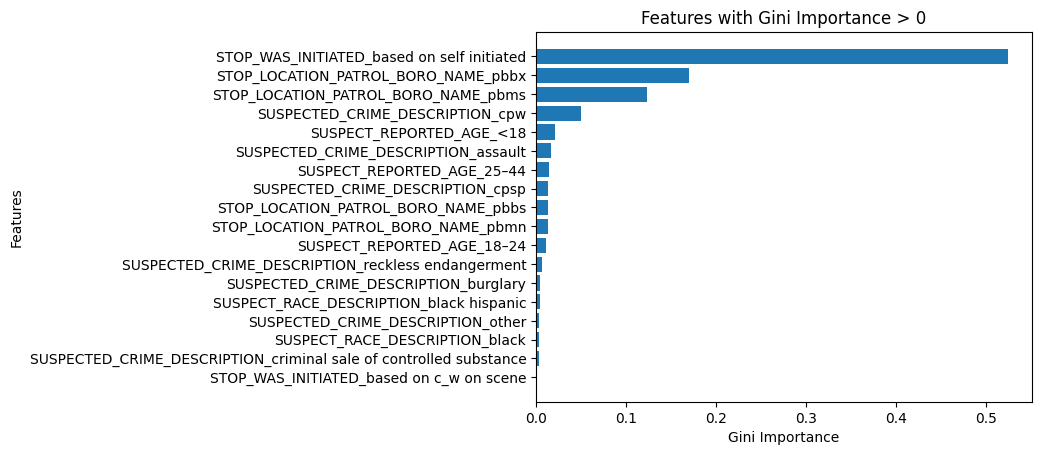

In [5]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_dt_model = dt_grid_search.best_estimator_

# Extract the Gini importances from the best model
dt_importances = best_dt_model.feature_importances_
dt_feature_importances = pd.Series(dt_importances, index=X_train.columns)

print("Using the tuned hyperparameter, the Gini importance (feature contribution) for each feature is:")
print()
print(dt_feature_importances.sort_values(ascending=False))

dt_plot_df = dt_feature_importances[dt_feature_importances > 0].sort_values(ascending=True)

plt.figure()
plt.barh(dt_plot_df.index, dt_plot_df.values)
plt.title("Features with Gini Importance > 0")
plt.xlabel("Gini Importance")
plt.ylabel("Features")
plt.show()

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameter (based on recall)

              precision    recall  f1-score   support

           0       0.87      0.55      0.67      4107
           1       0.30      0.69      0.41      1131

    accuracy                           0.58      5238
   macro avg       0.58      0.62      0.54      5238
weighted avg       0.74      0.58      0.62      5238



<Figure size 640x480 with 0 Axes>

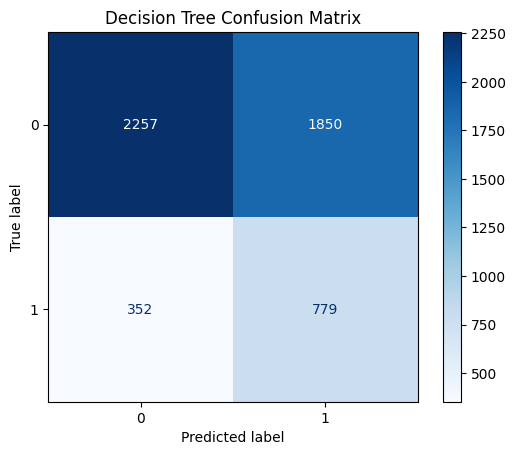

In [6]:
dt_y_pred = best_dt_model.predict(X_test)
print(classification_report(y_test, dt_y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, dt_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_dt_model.classes_)

plt.figure()
disp.plot(cmap="Blues", values_format="d")
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Main analysis (random forest)

### Create a random forest model and tune hyperparameters

In [7]:
# Initialize random forest model
rf = RandomForestClassifier(class_weight="balanced", random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid_rf = {
    "max_depth": [3, 5, 10, 20, None],
    "n_estimators": [50, 100, 200]
}

# Initialize GridSearchCV, with tuning based on recall (our primary metric)
rf_grid_search = GridSearchCV(
    rf,
    param_grid=param_grid_rf,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
)

# Run GridSearchCV
rf_grid_search.fit(X_train, y_train)

print(f"We evaluated 5 maximum depth values and 3 tree counts across 5 cross-validation folds, totaling 75 experimental fits. Using recall as our metric, the best hyperparameters were {rf_grid_search.best_params_}, which achieved a score of {rf_grid_search.best_score_:.2f}.")

We evaluated 5 maximum depth values and 3 tree counts across 5 cross-validation folds, totaling 75 experimental fits. Using recall as our metric, the best hyperparameters were {'max_depth': 5, 'n_estimators': 200}, which achieved a score of 0.67.


### Display results

param_max_depth  param_n_estimators  mean_test_accuracy  rank_test_accuracy  mean_test_precision  rank_test_precision  mean_test_recall  rank_test_recall  mean_test_f1  rank_test_f1
              3                  50                0.60                  10                 0.30                   10              0.63                 8          0.41             7
              3                 100                0.59                  11                 0.30                   11              0.65                 5          0.41             9
              3                 200                0.59                  12                 0.30                   15              0.66                 4          0.41             8
              5                  50                0.58                  13                 0.30                   12              0.67                 2          0.41             5
              5                 100                0.58                  14               

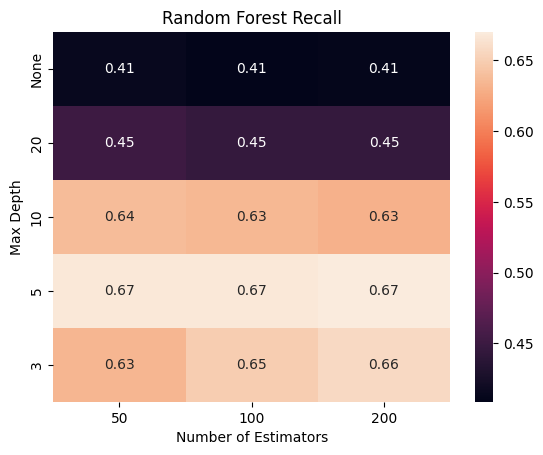

In [8]:
rf_grid_search_results = pd.DataFrame(rf_grid_search.cv_results_)

rf_results_table = rf_grid_search_results[[
    "param_max_depth",
    "param_n_estimators",
    "mean_test_accuracy", "rank_test_accuracy",
    "mean_test_precision", "rank_test_precision",
    "mean_test_recall", "rank_test_recall",
    "mean_test_f1", "rank_test_f1"]].copy()

print(rf_results_table.to_string(index=False, float_format="%.2f"))

plt.figure()

max_depth_order = ["None", "20", "10", "5", "3"]

rf_grid_search_results["param_max_depth"] = pd.Categorical(
    rf_grid_search_results["param_max_depth"].fillna("None").astype(str), 
    categories=max_depth_order, 
    ordered=True
)

rf_plot = rf_grid_search_results.pivot(
    index="param_max_depth", 
    columns="param_n_estimators", 
    values="mean_test_recall"
)

seaborn.heatmap(rf_plot, annot=True)
plt.title("Random Forest Recall")
plt.xlabel("Number of Estimators")
plt.ylabel("Max Depth")
plt.show()

### Interpret model

Using the tuned hyperparameters, the Gini importance (feature contribution) for each feature is:

STOP_WAS_INITIATED_based on self initiated                                 0.263362
SUSPECTED_CRIME_DESCRIPTION_cpw                                            0.183764
STOP_LOCATION_PATROL_BORO_NAME_pbbx                                        0.123371
STOP_LOCATION_PATROL_BORO_NAME_pbms                                        0.112279
SUSPECTED_CRIME_DESCRIPTION_assault                                        0.044069
STOP_WAS_INITIATED_based on c_w on scene                                   0.039398
SUSPECT_REPORTED_AGE_18–24                                                 0.037380
SUSPECTED_CRIME_DESCRIPTION_robbery                                        0.026499
SUSPECTED_CRIME_DESCRIPTION_petit larceny                                  0.016408
SUSPECTED_CRIME_DESCRIPTION_menacing                                       0.014174
STOP_LOCATION_PATROL_BORO_NAME_pbmn                           

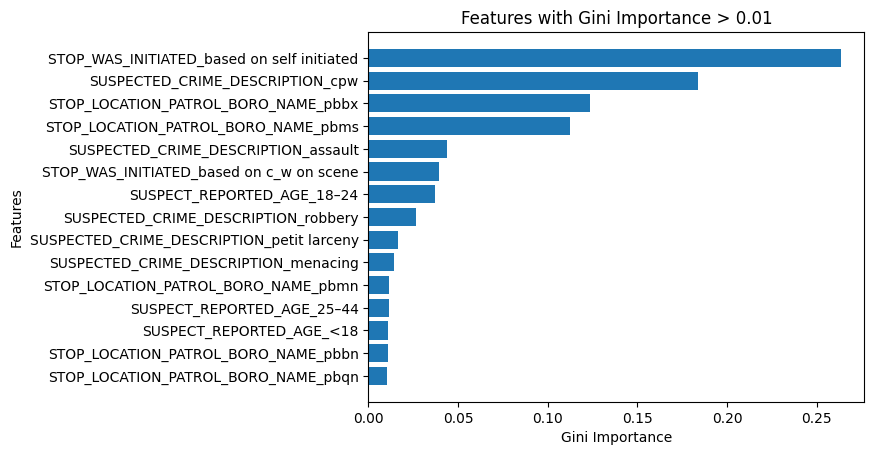

In [9]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_rf_model = rf_grid_search.best_estimator_

# Extract the Gini importances from the best model
rf_importances = best_rf_model.feature_importances_
rf_feature_importances = pd.Series(rf_importances, index=X_train.columns)

print("Using the tuned hyperparameters, the Gini importance (feature contribution) for each feature is:")
print()
print(rf_feature_importances.sort_values(ascending=False))

rf_plot_df = rf_feature_importances[rf_feature_importances > 0.01].sort_values(ascending=True)

plt.figure()
plt.barh(rf_plot_df.index, rf_plot_df.values)
plt.title("Features with Gini Importance > 0.01")
plt.xlabel("Gini Importance")
plt.ylabel("Features")
plt.show()

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameters (based on recall)

              precision    recall  f1-score   support

           0       0.86      0.55      0.68      4107
           1       0.30      0.69      0.41      1131

    accuracy                           0.58      5238
   macro avg       0.58      0.62      0.55      5238
weighted avg       0.74      0.58      0.62      5238



<Figure size 640x480 with 0 Axes>

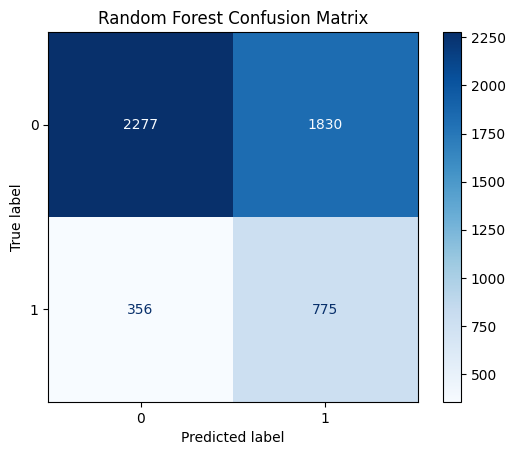

In [10]:
rf_y_pred = best_rf_model.predict(X_test)
print(classification_report(y_test, rf_y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, rf_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_rf_model.classes_)

plt.figure()
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.show()

# Compare decision tree and random forest models

   Metric  Decision Tree  Random Forest
   Recall          0.703          0.670
Precision          0.286          0.296
 Accuracy          0.555          0.583
 F1-Score          0.407          0.411


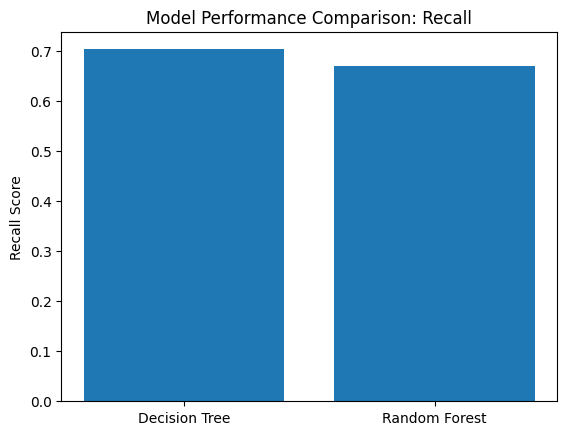

In [11]:
results = {
    "Metric": ["Recall", "Precision", "Accuracy", "F1-Score"],
    "Decision Tree": [
        dt_grid_search.best_score_, 
        dt_grid_search.cv_results_['mean_test_precision'][dt_grid_search.best_index_],
        dt_grid_search.cv_results_['mean_test_accuracy'][dt_grid_search.best_index_],
        dt_grid_search.cv_results_['mean_test_f1'][dt_grid_search.best_index_]
    ],
    "Random Forest": [
        rf_grid_search.best_score_, 
        rf_grid_search.cv_results_['mean_test_precision'][rf_grid_search.best_index_],
        rf_grid_search.cv_results_['mean_test_accuracy'][rf_grid_search.best_index_],
        rf_grid_search.cv_results_['mean_test_f1'][rf_grid_search.best_index_]
    ]
}

comparison_df = pd.DataFrame(results)

print(comparison_df.to_string(index=False, float_format="%.3f"))

plt.figure()

bars = plt.bar(["Decision Tree", "Random Forest"], [dt_grid_search.best_score_, rf_grid_search.best_score_])
plt.title("Model Performance Comparison: Recall")
plt.ylabel("Recall Score")
plt.show()